# Microburbs API: your first 10 minutes in Python

This walks through the Microburbs Hackathon API from a blank page to a table and a
chart covering every suburb in the City of Sydney. Each step is a few lines you can
copy into your own project.

1. Set your key
2. Find a suburb and an address
3. Look up one property: profile, valuation and sale history
4. Build a table of market figures for all 29 suburbs
5. Chart it
6. Pull a Census figure from area statistics

The same steps live in `quickstart.py` (run it with `python quickstart.py`) and in
`quickstart.ipynb`. API docs: https://api-ht.microburbs.com.au/docs

## 1. Set your key

The API needs your team's key on every request. Keep it out of your code: put it in an
environment variable called `MICROBURBS_API_KEY`. The easiest way is a `.env` file next to
this script (copy `.env.example` and paste your key in); `load_dotenv()` reads it.

`Microburbs` is the small helper client in `microburbs_client.py`. It adds the key to
each request, unwraps the `{"data": ...}` envelope, and waits and retries if you hit the
rate limit. Copy it into your own project.

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from matplotlib.ticker import FuncFormatter

from microburbs_client import Microburbs

load_dotenv()  # reads MICROBURBS_API_KEY from .env if you have one
mb = Microburbs()

try:
    show = display  # in Jupyter: render tables nicely
except NameError:
    show = print  # in a plain script: print them
    pd.set_option("display.width", 200, "display.max_columns", 20)

print(mb.get("/v1/ping"))

{'ok': True, 'service': 'microburbs-api', 'version': '1.0.0'}


## 2. Find a suburb and an address

Suburbs are named by their official ABS name, and some carry a suffix: it's
`Glebe (NSW)`, not `Glebe`. `/v1/geocode/suburb` turns whatever a user typed into the
exact name the other endpoints expect.

In [2]:
for match in mb.get("/v1/geocode/suburb", q="glebe"):
    print(match["area_name"], "|", match["information"]["lga"], "|", match["information"]["poa"])

Glebe (NSW) | Sydney | 2037


Addresses work the same way. `/v1/geocode/address` returns matching addresses, each with a
**GNAF id** (Australia's national address identifier). Every property endpoint is keyed
by that id.

In [3]:
matches = mb.get("/v1/geocode/address", address="26 Tudor Street, Surry Hills")
for m in matches:
    print(m["id"], "|", m["name"], "|", m["property_type"])

gnaf_id = matches[0]["id"]

GANSW705970502 | 26 Tudor Street, Surry Hills | house


## 3. One property: profile, valuation and sale history

With a GNAF id you can ask about the property itself. Three useful starting points:

- `/profile`: which suburb, postcode and statistical areas it sits in;
- `/valuation/avm`: an automated estimate of what it's worth today, with a range;
- `/sale-history`: every recorded sale.

In [4]:
profile = mb.get(f"/v1/properties/{gnaf_id}/profile")
print(f"Suburb: {profile['suburb']} {profile['postcode']}  |  LGA: {profile['lga']}")

basics = mb.get(f"/v1/properties/{gnaf_id}/basics/all")
print(f"{basics['dwelling_type']}, {basics['bed_count']} bed, {basics['bath_count']} bath")

avm = mb.get(f"/v1/properties/{gnaf_id}/valuation/avm")
if avm:
    print(
        f"Estimated value: ${avm['predicted_price']:,.0f} "
        f"(range ${avm['predicted_price_low']:,.0f} to ${avm['predicted_price_high']:,.0f}, "
        f"confidence {avm['confidence_score']}/100, as of {avm['prediction_date']})"
    )

sales = mb.get(f"/v1/properties/{gnaf_id}/sale-history") or []
show(pd.DataFrame(sales))

Suburb: Surry Hills 2010  |  LGA: Sydney
house, 3 bed, 1 bath


Estimated value: $2,003,839 (range $1,302,496 to $2,705,183, confidence 65/100, as of 2026-07-27)


,date,price,type,address
0,2015-11-27,1875000.0,Sold,26 Tudor Street
1,2004-11-18,735000.0,Sold,26 Tudor Street


## 4. All 29 City of Sydney suburbs in one table

`/v1/suburbs/list` returns every suburb your key covers. For each one we fetch five
small market endpoints and keep a handful of figures.

The City of Sydney is mostly apartments, so we focus on **units** (with the median house
price alongside for comparison). Prices are dollars, rents are dollars a week, and yield and
growth come back as fractions (0.045 means 4.5%).

Two things to notice:

- **Be polite.** 29 suburbs × 5 endpoints is 145 requests. We run 4 at a time, well under
  the limit (about 10 a second). The client waits and retries if we ever get a 429.
- **Data can be missing.** Some suburbs have too few sales for a figure, and then the API
  answers `{"data": null, "available": false, ...}`. The client returns `None`, and we
  record a blank rather than crash.

In [5]:
suburbs = [s["suburb"] for s in mb.get("/v1/suburbs/list")]
print(len(suburbs), "suburbs:", ", ".join(suburbs))


def market_row(suburb: str) -> dict:
    """A few headline market figures for one suburb. Missing data becomes None."""
    base = f"/v1/suburbs/{suburb}/market"
    price = mb.get(f"{base}/median-sale-price") or {}
    rent = mb.get(f"{base}/median-rent") or {}
    yld = mb.get(f"{base}/yield-pct") or {}
    growth = (mb.get(f"{base}/price-growth") or {}).get("unit") or {}
    sales = mb.get(f"/v1/suburbs/{suburb}/sales/summary") or {}
    return {
        "suburb": suburb,
        "unit_median_price": price.get("unit"),
        "house_median_price": price.get("house"),
        "unit_weekly_rent": rent.get("unit"),
        "unit_gross_yield": yld.get("unit"),
        "unit_growth_1y": growth.get("1yr"),
        "unit_growth_5y": growth.get("5yr"),
        "sales_3y": sales.get("sales_count_3y"),  # all dwellings, last 3 years
    }


with ThreadPoolExecutor(max_workers=4) as pool:
    rows = list(pool.map(market_row, suburbs))

df = pd.DataFrame(rows).set_index("suburb").sort_values("unit_median_price", ascending=False)

Path("out").mkdir(exist_ok=True)
df.to_csv("out/city_of_sydney_market.csv")



def fmt(template: str):
    """Formatter for one column: blank where the API had no data."""
    return lambda v: "" if pd.isna(v) else template.format(v)


# A copy formatted for reading: dollars and percentages.
show(
    df.assign(
        unit_median_price=df["unit_median_price"].map(fmt("${:,.0f}")),
        house_median_price=df["house_median_price"].map(fmt("${:,.0f}")),
        unit_weekly_rent=df["unit_weekly_rent"].map(fmt("${:,.0f}")),
        unit_gross_yield=df["unit_gross_yield"].map(fmt("{:.1%}")),
        unit_growth_1y=df["unit_growth_1y"].map(fmt("{:+.1%}")),
        unit_growth_5y=df["unit_growth_5y"].map(fmt("{:+.1%}")),
        sales_3y=df["sales_3y"].map(fmt("{:,.0f}")),
    )
)

29 suburbs: Alexandria, Barangaroo, Beaconsfield (NSW), Camperdown (NSW), Centennial Park (NSW), Chippendale, Darlinghurst, Darlington (Sydney - NSW), Dawes Point, Elizabeth Bay, Erskineville, Eveleigh, Forest Lodge, Glebe (NSW), Haymarket, Millers Point, Moore Park, Potts Point, Pyrmont, Redfern, Rosebery (NSW), Rushcutters Bay, Surry Hills, Sydney, The Rocks (Sydney - NSW), Ultimo, Waterloo (NSW), Woolloomooloo, Zetland


,unit_median_price,house_median_price,unit_weekly_rent,unit_gross_yield,unit_growth_1y,unit_growth_5y,sales_3y
suburb,,,,,,,
Dawes Point,"$3,700,000","$4,300,000","$1,400",2.0%,+7.9%,-24.5%,18
Barangaroo,"$2,520,000",,"$2,000",4.1%,-49.6%,-80.5%,16
The Rocks (Sydney - NSW),"$2,020,000","$2,650,000","$1,300",3.3%,-6.9%,-10.0%,43
Millers Point,"$1,690,000","$2,650,000","$1,100",3.4%,-25.5%,-16.8%,92
Forest Lodge,"$1,400,000","$2,300,000",$850,3.2%,+45.8%,+50.5%,332
Beaconsfield (NSW),"$1,190,000","$2,400,000",$950,4.2%,-13.6%,+29.3%,84
Eveleigh,"$1,160,000","$10,000,000",$900,4.0%,+1.5%,+45.6%,20
Erskineville,"$1,110,000","$2,000,000",$950,4.4%,+6.0%,+16.2%,656
Pyrmont,"$1,090,000","$2,100,000",$950,4.5%,-1.5%,-9.4%,489


A quick sanity check: which figures are missing, and for how many suburbs?

Also look at `sales_3y`. A median from a few dozen sales jumps around: Barangaroo's
-80% five-year unit growth and Eveleigh's $10m median house price come from small,
unusual samples. Check the sales count before you trust a figure.

In [6]:
print(df.isna().sum().to_string())

unit_median_price     1
house_median_price    3
unit_weekly_rent      0
unit_gross_yield      1
unit_growth_1y        1
unit_growth_5y        1
sales_3y              1


## 5. A chart

Median unit price for every suburb, cheapest at the bottom. Suburbs with fewer than 100
sales in three years are drawn lighter, because their medians are less reliable. Plain
matplotlib on the DataFrame from step 4; the chart is also saved to `out/unit_prices.png`.

Saved out/unit_prices.png


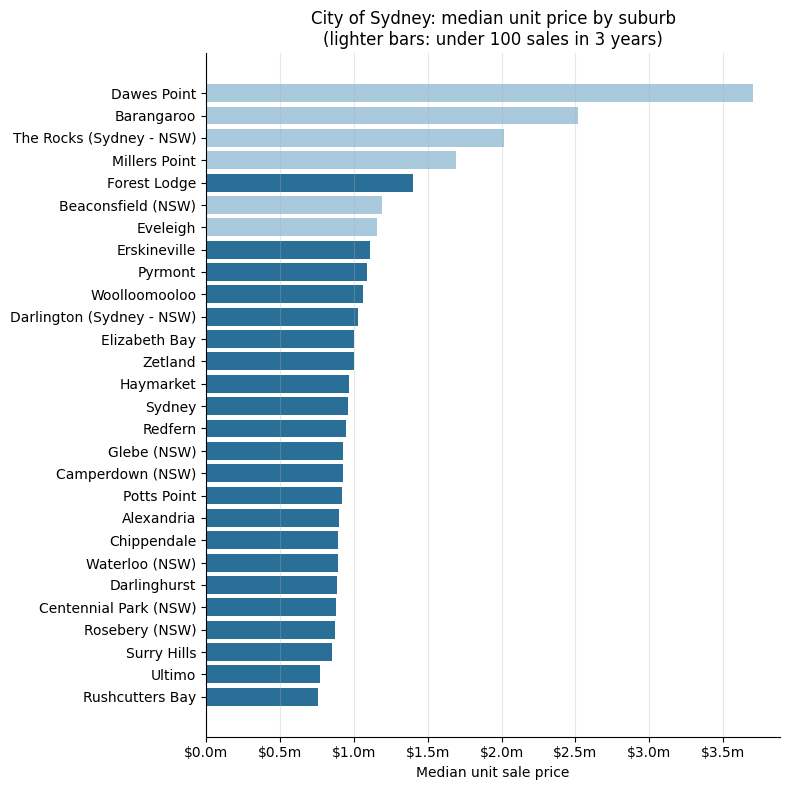

In [7]:
chart = df.dropna(subset=["unit_median_price"]).sort_values("unit_median_price")
thin = chart["sales_3y"].fillna(0) < 100
colours = ["#a9c9dd" if t else "#2a6f97" for t in thin]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(chart.index, chart["unit_median_price"], color=colours)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1e6:.1f}m"))
ax.set_xlabel("Median unit sale price")
ax.set_title("City of Sydney: median unit price by suburb\n(lighter bars: under 100 sales in 3 years)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("out/unit_prices.png", dpi=120)
print("Saved out/unit_prices.png")

## 6. Census data with area statistics

`/v1/area-stats` exposes about 17,000 ABS statistics (mostly the 2021 Census) for suburbs and
other areas. It works in two steps:

1. **Search for a field** with `/v1/area-stats/fields`. Searching is free.
2. **Fetch values** for a region with `/v1/area-stats/{level}/{region}/values`, passing up to
   5 field codes. `SAL` is the ABS name for the suburb level.

In [8]:
fields = mb.get("/v1/area-stats/fields", query="median age", limit=5)["fields"]
show(pd.DataFrame(fields)[["field_code", "label", "topic"]])

,field_code,label,topic
0,Median_age_persons,Median age of persons,Selected Medians and Averages
1,Median_mortgage_repay_monthly,Median mortgage repayment ($/monthly),Selected Medians and Averages
2,Median_rent_weekly,Median rent ($/weekly),Selected Medians and Averages
3,Average_household_size,Average household size,Selected Medians and Averages
4,Median_tot_fam_inc_weekly,Median total family income ($/weekly),Selected Medians and Averages


In [9]:
census = mb.get(
    "/v1/area-stats/SAL/Surry Hills/values",
    fields="Median_age_persons,Median_rent_weekly,Average_household_size",
)
print(f"{census['region_name']}, {census['year']} Census:")
for f in census["fields"]:
    print(f"  {f['label']}: {f['value']}")

Surry Hills, 2021 Census:
  Average household size: 1.8
  Median age of persons: 35.0
  Median rent ($/weekly): 550.0


Census rent is the median across all rented dwellings in 2021. Compare it with the current
median unit rent from step 4 to see how far asking rents have moved since.

In [10]:
census_rent = next(f["value"] for f in census["fields"] if f["field_code"] == "Median_rent_weekly")
today_rent = df.loc["Surry Hills", "unit_weekly_rent"]
print(f"Surry Hills weekly rent: ${census_rent:,.0f} (2021 Census, all dwellings) "
      f"vs ${today_rent:,.0f} (current median unit rent)")

Surry Hills weekly rent: $550 (2021 Census, all dwellings) vs $800 (current median unit rent)


## Where next

- Browse every endpoint at https://api-ht.microburbs.com.au/docs. Most suburb endpoints take
  the same `{suburb_name}` you used here, and property endpoints take a GNAF id.
- Need one figure for every suburb? Use the loop in step 4 with a different endpoint.
- Bundles such as `/market/all` or `/valuation/all` return several sections in one call.